# SPSA for Layer-Wise Training of Deep Networks: a notebook reproduction

**Paper:** B. Wulff, J. Schuecker, C. Bauckhage. *SPSA for Layer-Wise Training of Deep Networks.*
ICANN 2018, LNCS 11141, pp. 564–573. [doi:10.1007/978-3-030-01424-7_55](https://doi.org/10.1007/978-3-030-01424-7_55)

**Implementation by:** Ananth Shyam, Rama Narasimha and Mahan Bhimireddy.

The paper trains feed-forward `tanh` networks **without backpropagation**, using only forward passes.
It relies on Spall's *simultaneous perturbation stochastic approximation* (SPSA). Every update perturbs
the weights randomly in both directions, evaluates the error twice, and steps along the resulting
finite-difference estimate of the gradient. The authors compare two schemes:

* **holistic** SPSA: perturb *all* weights at once;
* **layer-wise** SPSA (Algorithm 2): update one layer at a time while the others stay fixed,
  visiting the layers bottom-up, top-down or in random order.

This notebook is **self-contained**: every piece of the method is written out below and follows the
paper section by section. Running it top to bottom reproduces every experiment:

| section | paper | content |
|---|---|---|
| 2 | Sect. 2, Algorithm 1, Eq. 4 | plain SPSA, tested on a sphere function |
| 3 | Sect. 3, Eqs. 5–9 | the network and the error function |
| 4 | Sect. 3, Algorithm 2, Eqs. 11–13 | layer-wise / holistic SPSA training |
| 5 | Sect. 4.1, Fig. 1 | xor, moons, circles: 4 variants × 100 trials |
| 6 | Sect. 4.2, Fig. 2 | MNIST: layer-wise SPSA vs gradient descent |
| 7 | Sect. 4.2 (text) | MNIST ablations: holistic SPSA, no weights/biases split |
| 7b | Sect. 4.2 | the literal 784×196×10 topology (155,830 parameters) for comparison |
| 8 | | summary and comparison with the paper |

**Run time** on an RTX 3050 laptop GPU with the paper settings is about 65 minutes; the circles
experiment takes ~45 of them and MNIST ~15. Set `QUICK = True` in the configuration cell for a run of a few minutes.

## 1. Setup

In [1]:
import json
import math
import time
import gzip
import shutil
import urllib.request
from dataclasses import dataclass, field, asdict
from pathlib import Path
from typing import List, Optional

import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

print(f"torch {torch.__version__} | CUDA available: {torch.cuda.is_available()}")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU (the MNIST part will be slow: ~25 s per epoch per run)")

torch 2.14.0+cu126 | CUDA available: True
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU


### Configuration

`QUICK = True` gives a smoke test of a few minutes: 10 trials, fewer epochs and 10k MNIST images.
`QUICK = False` is the paper protocol.

The data directory is the repository's `data/` folder when the notebook lives in `notebooks/`, and
`./data` otherwise. Results (JSON and PNG) go to `notebook_results/` next to the notebook.

In [2]:
QUICK = False                 # True: few-minute smoke test; False: paper protocol
N_TRIALS = 100                # trials per variant in Fig. 1 (paper: 100)
N_TRIALS_CIRCLES = 100        # circles is the slow one (100 trials ~45 min on an RTX 3050; 20 trials ~10 min)
MNIST_RUNS = 3                # independent SPSA runs on MNIST (paper averages 3 successful runs)
SEED = 0

if QUICK:
    N_TRIALS = N_TRIALS_CIRCLES = 10

NOTEBOOK_DIR = Path.cwd()
DATA_DIR = (NOTEBOOK_DIR.parent / "data") if (NOTEBOOK_DIR.parent / "spsa_nn").exists() else (NOTEBOOK_DIR / "data")
RESULTS_DIR = NOTEBOOK_DIR / ("notebook_results_quick" if QUICK else "notebook_results")
DATA_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print("data dir   :", DATA_DIR.resolve())
print("results dir:", RESULTS_DIR.resolve())

def seed_everything(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def make_generator(seed, device=DEVICE):
    # A torch.Generator on the compute device (CUDA generators avoid host syncs)
    g = torch.Generator(device=device if device.type == "cuda" else "cpu")
    g.manual_seed(seed)
    return g

seed_everything(SEED)
NOTEBOOK_T0 = time.perf_counter()

data dir   : D:\SPSA implementation\spsa-layerwise\data
results dir: D:\SPSA implementation\spsa-layerwise\notebooks\notebook_results


## 2. Algorithm 1: SPSA (paper Sect. 2)

We want $x^* = \arg\min_x f(x)$ for a function that we can only *evaluate*. SPSA approximates every
component of the gradient using just **two** evaluations of $f$, whatever the dimension $m$:

$$\hat g_i(x_t) = \frac{f(x_t + c_t\delta) - f(x_t - c_t\delta)}{2\,c_t\,\delta_i}, \qquad
\delta_i \sim \mathcal U\{-1,+1\}\quad\text{(Eq. 4)}$$

and descends: $x_{t+1} = x_t - a_t\,\hat g(x_t)$, with gains $a_t = a/t^\alpha$ and $c_t = c/t^\gamma$.

The perturbation entries must be zero-mean with finite inverse moments, which rules out Gaussians;
the paper uses Rademacher (±1) entries. For $\delta_i = \pm1$ we have $1/\delta_i = \delta_i$.

In [3]:
def rademacher_np(shape, rng):
    # Perturbation vector with i.i.d. entries uniform on {-1, +1}
    return rng.integers(0, 2, size=shape).astype(np.float64) * 2.0 - 1.0


def spsa_minimize(f, x0, a=0.1, alpha=1.0, c=0.1, gamma=1/6, t_max=1000, rng=None, callback=None):
    # Algorithm 1 of the paper, literally
    rng = np.random.default_rng() if rng is None else rng
    x = np.array(x0, dtype=np.float64, copy=True)
    for t in range(1, t_max + 1):
        a_t = a / t**alpha
        c_t = c / t**gamma
        delta = rademacher_np(x.shape, rng)
        x_plus = x + c_t * delta
        x_minus = x - c_t * delta
        g_hat = (f(x_plus) - f(x_minus)) / (2.0 * c_t * delta)
        x = x - a_t * g_hat
        if callback is not None:
            callback(t, x)
    return x

**Sanity check:** minimise the 10-dimensional sphere function $f(x)=\|x\|^2$ from $x_0 = (3,\dots,3)$.
Each step uses only 2 function evaluations, compared with 20 for central finite differences.

f(x_0) = 90.0   f(x_2000) = 2.21e-14

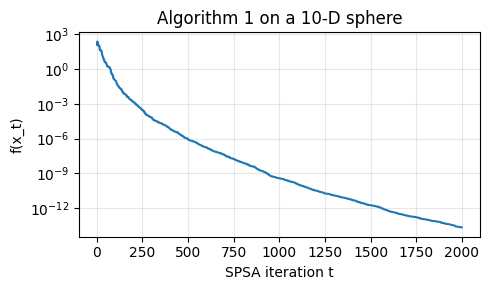

In [4]:
sphere = lambda x: float(np.sum(x**2))
trace = []
x_final = spsa_minimize(sphere, np.full(10, 3.0), a=0.2, alpha=0.602, c=0.1, gamma=0.101, t_max=2000,
                        rng=np.random.default_rng(0), callback=lambda t, x: trace.append(sphere(x)))
print(f"f(x_0) = {sphere(np.full(10, 3.0)):.1f}   f(x_2000) = {sphere(x_final):.2e}")

plt.figure(figsize=(5, 3))
plt.semilogy(np.arange(1, len(trace) + 1), trace)
plt.xlabel("SPSA iteration t"); plt.ylabel("f(x_t)"); plt.title("Algorithm 1 on a 10-D sphere")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 3. The network and the error function (paper Sect. 3, Eqs. 5–9)

Each layer computes $a^l = h^l(W^l a^{l-1})$ with $h(z) = \tanh(\beta z)$, and the bias is part of
the weighted sum (Eqs. 5–6). The network is $y(x\mid\mathcal W) = h^L(W^L h^{L-1}(\dots h^1(W^1x)))$ (Eq. 7).
The training objective is the **sum of squared residuals** (Eq. 9):

$$E(\mathcal D, \mathcal W) = \sum_{i=1}^n \|y(x_i\mid\mathcal W) - y_i\|^2$$

**Implementation trick:** every tensor gets a leading **trial axis K**. Instead of training the paper's
100 random initialisations one after another, all 100 networks are trained at once. Each has its own
weights, its own perturbations and its own finite difference, and one batched forward pass on the GPU
evaluates them all. With K = 1 this is an ordinary network.

Parameters are stored as a flat list `[W1, b1, W2, b2, ...]` with `W_l: (K, n_out, n_in)` and `b_l: (K, n_out)`.

In [5]:
def init_params(sizes, n_trials=1, init="glorot", device=DEVICE, dtype=torch.float32, generator=None):
    # 'standard': W, b ~ N(0, 1)   (tf.random_normal; matches the initial errors of Fig. 1)
    # 'glorot'  : W ~ U(+-sqrt(6/(n_in+n_out))), b = 0   (TF dense default; matches Fig. 2)
    params = []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        shape = (n_trials, n_out, n_in)
        if init == "glorot":
            r = math.sqrt(6.0 / (n_in + n_out))
            W = (torch.rand(shape, generator=generator, device=device, dtype=dtype) * 2 - 1) * r
            b = torch.zeros((n_trials, n_out), device=device, dtype=dtype)
        elif init == "standard":
            W = torch.randn(shape, generator=generator, device=device, dtype=dtype)
            b = torch.randn((n_trials, n_out), generator=generator, device=device, dtype=dtype)
        else:
            raise ValueError(init)
        params += [W, b]
    return params


def count_parameters(sizes):
    return sum(n_in * n_out + n_out for n_in, n_out in zip(sizes[:-1], sizes[1:]))


def layer_forward(a_prev, W, b, beta):
    # a_prev: (N, n_in) shared input or (K, N, n_in)  ->  (K, N, n_out)
    return torch.tanh(beta * (torch.matmul(a_prev, W.transpose(-1, -2)) + b.unsqueeze(-2)))


def forward(x, params, beta, start_layer=0):
    # Eq. 7. With start_layer = l > 0, x must already be a^l (the cached output of the fixed layers below)
    a = x
    for l in range(start_layer, len(params) // 2):
        a = layer_forward(a, params[2 * l], params[2 * l + 1], beta)
    return a


def activations_upto(x, params, beta, layer):
    a = x
    for l in range(layer):
        a = layer_forward(a, params[2 * l], params[2 * l + 1], beta)
    return a


def error(y_hat, y, reduction="sum"):
    # Eq. 9 per trial -> (K,).  'mean' = Eq. 9 / n,  'elementwise_mean' = Eq. 9 / (n*m) = tf.reduce_mean
    per_sample = (y_hat - y).pow(2).sum(dim=-1)
    if reduction == "sum":
        return per_sample.sum(dim=-1)
    if reduction == "mean":
        return per_sample.mean(dim=-1)
    if reduction == "elementwise_mean":
        return per_sample.mean(dim=-1) / y.shape[-1]
    raise ValueError(reduction)


@torch.no_grad()
def evaluate_error(x, y, params, beta, reduction="sum", chunk=20000):
    total = None
    for i in range(0, x.shape[0], chunk):
        e = error(forward(x[i:i + chunk], params, beta), y[i:i + chunk], "sum")
        total = e if total is None else total + e
    n = x.shape[0]
    return {"sum": total, "mean": total / n, "elementwise_mean": total / (n * y.shape[-1])}[reduction]


@torch.no_grad()
def predict_classes(x, params, beta, chunk=20000):
    # One output: class = (y > 0); several outputs: argmax
    out = []
    for i in range(0, x.shape[0], chunk):
        y_hat = forward(x[i:i + chunk], params, beta)
        out.append((y_hat[..., 0] > 0).long() if y_hat.shape[-1] == 1 else y_hat.argmax(-1))
    return torch.cat(out, dim=1)


@torch.no_grad()
def accuracy(x, labels, params, beta):
    return (predict_classes(x, params, beta) == labels.unsqueeze(0)).float().mean(dim=1)


for sizes in ([2, 5, 5, 5, 1], [2, 10, 10, 10, 10, 10, 3], [784, 196, 10], [784, 784, 196, 10]):
    print(f"{'x'.join(map(str, sizes)):>24s}: {count_parameters(sizes):>7,d} parameters")

               2x5x5x5x1:      81 parameters
      2x10x10x10x10x10x3:     503 parameters
              784x196x10: 155,830 parameters
          784x784x196x10: 771,270 parameters


The first two counts match the paper (81 and 503). For MNIST the paper is inconsistent. It describes
the topology as 784×196×10, which has only **155,830** parameters, but it states **771,270**
parameters. It also repeats that SPSA trains networks *"close to a million"* parameters (p. 571 and the
conclusion). Adding one 784-unit hidden layer, **784×784×196×10**, gives exactly 771,270.

Since the parameter count is stated three times and the topology only once, this notebook trains the
**771,270-parameter network** as the main MNIST experiment. The literal 784×196×10 network is run
for comparison in Section 7b.

## 4. Algorithm 2: layer-wise SPSA training (paper Sect. 3)

Each **epoch** visits the layers in some order (Eqs. 11–13):

* bottom-up $\{1, \dots, L\}$, top-down $\{L, \dots, 1\}$, or a random permutation (drawn independently
  per trial and per epoch).

For each visited layer *l*, **all other weight matrices are kept fixed** and Algorithm 1 is run for
$t = 1..t_{max}$ on $W^l$ alone. The gains restart at $a_1, c_1$ on every call, which is the "warm
restart" mentioned in the paper's conclusion. **Holistic** SPSA perturbs every parameter in each call.
To give it the same number of forward passes, it makes L calls per epoch.

The MNIST modification of Sect. 4.2 (`split_bias=True`) handles each layer as two SPSA calls: first
its weights, then its biases.

**Efficiency tricks** (they leave the algorithm unchanged):
1. The layers below the active one are fixed during a call, so their output is computed **once** and cached.
2. The + and − perturbations are stacked into one batch of 2K networks: one forward pass gives both $f(x^+)$ and $f(x^-)$.
3. A per-trial mask allows different trials to train different layers in the same call (needed for the random order).

In [6]:
ORDERS = ("bottom-up", "top-down", "random", "holistic")


@dataclass
class SPSAConfig:
    a: float = 0.1        # step-size gain
    c: float = 0.1        # perturbation gain
    alpha: float = 1.0    # a_t = a / t^alpha
    gamma: float = 1 / 6  # c_t = c / t^gamma
    t_max: int = 50       # SPSA iterations per call of Algorithm 1


@dataclass
class TrainConfig:
    sizes: List[int]
    order: str = "bottom-up"
    epochs: int = 25
    beta: float = 0.5
    n_trials: int = 1
    reduction: str = "sum"                 # objective used inside SPSA
    report_reduction: Optional[str] = None # scale of the logged error (default = reduction)
    split_bias: bool = False               # Sect. 4.2: weights first, then biases
    init: str = "standard"
    seed: int = 0
    spsa: SPSAConfig = field(default_factory=SPSAConfig)


def epoch_schedule(order, n_layers, n_trials, split_bias, generator):
    # List of SPSA calls for one epoch; each is a bool mask (n_params, n_trials): which tensors are trained
    P = 2 * n_layers
    if order == "holistic":
        return [torch.ones(P, n_trials, dtype=torch.bool) for _ in range(n_layers)]
    if order == "bottom-up":
        perms = [list(range(n_layers))] * n_trials                            # Eq. 12
    elif order == "top-down":
        perms = [list(range(n_layers - 1, -1, -1))] * n_trials                # Eq. 11
    elif order == "random":
        perms = [torch.randperm(n_layers, generator=generator).tolist() for _ in range(n_trials)]  # Eq. 13
    else:
        raise ValueError(order)
    groups = [[0], [1]] if split_bias else [[0, 1]]   # offsets of W and b inside a layer
    steps = []
    for s in range(n_layers):
        for g in groups:
            mask = torch.zeros(P, n_trials, dtype=torch.bool)
            for k in range(n_trials):
                for off in g:
                    mask[2 * perms[k][s] + off, k] = True
            steps.append(mask)
    return steps


@torch.no_grad()
def spsa_call(params, active, x, y, cfg, generator):
    # One call of Algorithm 1 on the active parameter tensors, in place, for all K trials at once
    K = params[0].shape[0]
    device, dtype = params[0].device, params[0].dtype
    active_idx = [p for p in range(len(params)) if bool(active[p].any())]
    start_layer = min(active_idx) // 2

    a_in = activations_upto(x, params, cfg.beta, start_layer)      # trick 1: cache the fixed layers below
    if a_in.dim() == 3:
        a_in = torch.cat([a_in, a_in], dim=0)                      # trick 2: [+ | -] stacked as 2K trials
    fixed = {p: torch.cat([params[p], params[p]], dim=0)
             for p in range(2 * start_layer, len(params)) if p not in active_idx}
    masks = {p: None if bool(active[p].all())
             else active[p].to(device=device, dtype=dtype).view(K, *([1] * (params[p].dim() - 1)))
             for p in active_idx}                                   # trick 3: per-trial masks

    for t in range(1, cfg.spsa.t_max + 1):
        a_t = cfg.spsa.a / t**cfg.spsa.alpha
        c_t = cfg.spsa.c / t**cfg.spsa.gamma
        deltas, both = {}, list(params)
        for p in range(2 * start_layer, len(params)):
            if p in fixed:
                both[p] = fixed[p]
                continue
            d = torch.randint(0, 2, params[p].shape, generator=generator, device=device).to(dtype).mul_(2).sub_(1)
            if masks[p] is not None:
                d.mul_(masks[p])                 # trials that do not train this tensor: delta = 0
            deltas[p] = d
            both[p] = torch.cat([params[p] + c_t * d, params[p] - c_t * d], dim=0)
        f_both = error(forward(a_in, both, cfg.beta, start_layer), y, cfg.reduction)
        g_scale = (f_both[:K] - f_both[K:]) / (2.0 * c_t)           # (f+ - f-) / (2 c_t), per trial
        g_scale = torch.nan_to_num(g_scale, nan=0.0, posinf=0.0, neginf=0.0)
        for p in active_idx:                                        # x <- x - a_t * g_hat, with 1/delta = delta
            params[p].sub_((a_t * g_scale).view(K, *([1] * (params[p].dim() - 1))) * deltas[p])


@torch.no_grad()
def train_spsa(x, y, cfg, eval_fn=None, log_every=0, tag=""):
    # Algorithm 2. Returns (params, history); history['error'][e] = per-trial E after epoch e (0 = init)
    x, y = x.to(DEVICE), y.to(DEVICE)
    gen = make_generator(cfg.seed)
    cpu_gen = torch.Generator().manual_seed(cfg.seed + 1)
    params = init_params(cfg.sizes, cfg.n_trials, cfg.init, DEVICE, x.dtype, gen)
    L = len(params) // 2
    hist = {"error": [], "time": []}
    rep = cfg.report_reduction or cfg.reduction

    def record(elapsed):
        hist["error"].append(evaluate_error(x, y, params, cfg.beta, rep).cpu().tolist())
        hist["time"].append(elapsed)
        if eval_fn is not None:
            for k, v in eval_fn(params).items():
                hist.setdefault(k, []).append(v.cpu().tolist())

    t0 = time.perf_counter()
    record(0.0)
    for e in range(1, cfg.epochs + 1):
        for active in epoch_schedule(cfg.order, L, cfg.n_trials, cfg.split_bias, cpu_gen):
            spsa_call(params, active, x, y, cfg, gen)
        record(time.perf_counter() - t0)
        if log_every and (e % log_every == 0 or e == cfg.epochs):
            err = torch.tensor(hist["error"][-1])
            extra = "".join(f"  {k} {np.mean(v[-1]):.4f}" for k, v in hist.items() if k not in ("error", "time"))
            print(f"{tag}epoch {e:4d}/{cfg.epochs}  E mean {err.mean():9.3f}  median {err.median():9.3f}{extra}"
                  f"  ({hist['time'][-1]:.1f}s)", flush=True)
    return params, hist

**Unit checks** before the experiments:
* every schedule trains every layer exactly once per epoch (holistic: everything L times);
* an SPSA call on layer 2 leaves all other layers untouched.

In [7]:
_g = torch.Generator().manual_seed(0)
for order in ORDERS:
    steps = epoch_schedule(order, n_layers=4, n_trials=3, split_bias=False, generator=_g)
    counts = torch.stack(steps).sum(0)
    assert (counts == (4 if order == "holistic" else 1)).all(), order
steps = epoch_schedule("bottom-up", 2, 1, split_bias=True, generator=_g)
assert [torch.nonzero(s[:, 0]).flatten().tolist() for s in steps] == [[0], [1], [2], [3]]  # W1, b1, W2, b2

_p = init_params([2, 5, 5, 1], n_trials=4, init="standard", generator=make_generator(0))
_before = [p.clone() for p in _p]
_mask = torch.zeros(6, 4, dtype=torch.bool); _mask[2:4] = True
spsa_call(_p, _mask, torch.randn(40, 2, device=DEVICE), torch.ones(40, 1, device=DEVICE),
          TrainConfig(sizes=[2, 5, 5, 1], spsa=SPSAConfig(a=0.01, t_max=5)), make_generator(1))
assert all(torch.equal(_p[i], _before[i]) for i in (0, 1, 4, 5)) and not torch.equal(_p[2], _before[2])
print("all checks passed")

all checks passed


## 5. Sect. 4.1: didactic classification problems (Fig. 1)

### Data

The paper shows the three data sets but does not give their exact generation or size. These
generators match the pictures. The sizes (200 / 200 / 120 points) are chosen so that the **initial
errors match Fig. 1** (≈ 270, 265 and 400 with N(0,1) initialisation).

* **xor**: 4 Gaussian blobs, 2 classes, labels $y\in\{-1,+1\}$
* **moons**: two interleaved half circles, 2 classes, $y\in\{-1,+1\}$
* **circles**: 3 concentric rings, 3 classes, $y\in\{-1,+1\}^3$ (+1 for the true class)

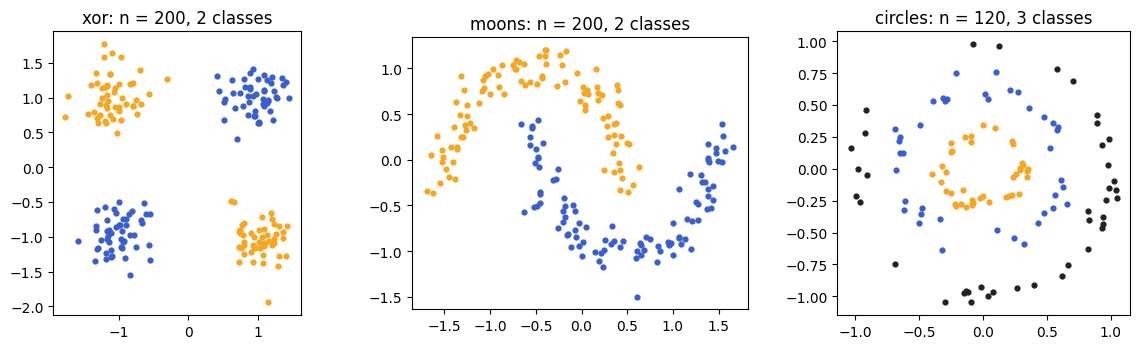

In [8]:
@dataclass
class Dataset:
    x: torch.Tensor
    y: torch.Tensor
    labels: torch.Tensor
    n_classes: int


def _two_class(x, labels):
    y = np.where(labels == 1, 1.0, -1.0)[:, None]
    return Dataset(torch.tensor(x, dtype=torch.float32), torch.tensor(y, dtype=torch.float32),
                   torch.tensor(labels, dtype=torch.long), 2)


def make_xor(n=200, noise=0.25, seed=0):
    rng = np.random.default_rng(seed)
    centers = np.array([[-1, -1], [1, 1], [-1, 1], [1, -1]], dtype=float)
    blob = np.repeat(np.arange(4), n // 4) if n % 4 == 0 else rng.integers(0, 4, size=n)
    x = centers[blob] + noise * rng.standard_normal((n, 2))
    return _two_class(x, (blob < 2).astype(int))


def make_moons(n=200, noise=0.1, seed=0):
    rng = np.random.default_rng(seed)
    n_out, n_in = n // 2, n - n // 2
    t_out, t_in = np.linspace(0, np.pi, n_out), np.linspace(0, np.pi, n_in)
    x = np.concatenate([np.stack([np.cos(t_out), np.sin(t_out)], 1),
                        np.stack([1 - np.cos(t_in), 1 - np.sin(t_in) - 0.5], 1)])
    x = (x + noise * rng.standard_normal((n, 2)) - [0.5, 0.25]) / [1.0, 0.75]
    return _two_class(x, np.concatenate([np.zeros(n_out, int), np.ones(n_in, int)]))


def make_circles(n=120, noise=0.05, seed=0, radii=(0.3, 0.65, 1.0)):
    rng = np.random.default_rng(seed)
    k = len(radii)
    labels = np.repeat(np.arange(k), int(np.ceil(n / k)))[:n]
    theta = rng.uniform(0, 2 * np.pi, n)
    r = np.asarray(radii)[labels]
    x = np.stack([r * np.cos(theta), r * np.sin(theta)], 1) + noise * rng.standard_normal((n, 2))
    y = -np.ones((n, k)); y[np.arange(n), labels] = 1.0
    return Dataset(torch.tensor(x, dtype=torch.float32), torch.tensor(y, dtype=torch.float32),
                   torch.tensor(labels, dtype=torch.long), k)


DATASETS = {"xor": make_xor(), "moons": make_moons(), "circles": make_circles()}
CLASS_COLORS = ["#f5a623", "#3a5fcd", "#222222"]
REGION_COLORS = ["#fde7bd", "#c3cfec", "#bdbdbd"]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (name, d) in zip(axes, DATASETS.items()):
    for k in range(d.n_classes):
        m = (d.labels == k).numpy()
        ax.scatter(d.x[m, 0], d.x[m, 1], s=12, c=CLASS_COLORS[k])
    ax.set_title(f"{name}: n = {len(d.x)}, {d.n_classes} classes"); ax.set_aspect("equal")
plt.tight_layout(); plt.show()

### Settings

**From the paper:**
* architectures 2×5×5×5×1 (xor, moons) and 2×10×10×10×10×10×3 (circles), each with bias units;
* β = 0.5 / 0.25;
* the Eq. 9 sum objective;
* 25 / 25 / 500 epochs;
* 100 trials averaged.

**Not in the paper, chosen here:**
* N(0,1) initialisation, which matches the initial error of Fig. 1;
* $c = 0.1$, $\alpha = 1$, $\gamma = 1/6$, $t_{max} = 50$, all inside the paper's stated ranges
  ($\alpha \ge 1$, $\gamma \in [1/6, 1/2]$);
* $a$ tuned per data set: xor 0.01, moons 0.02, circles 0.005.

In [9]:
FIG1 = {
    "xor":     dict(sizes=[2, 5, 5, 5, 1],             beta=0.5,  epochs=25,  a=0.01,  trials=N_TRIALS),
    "moons":   dict(sizes=[2, 5, 5, 5, 1],             beta=0.5,  epochs=25,  a=0.02,  trials=N_TRIALS),
    "circles": dict(sizes=[2, 10, 10, 10, 10, 10, 3],  beta=0.25, epochs=500, a=0.005, trials=N_TRIALS_CIRCLES),
}
if QUICK:
    for p in FIG1.values():
        p["epochs"] = max(5, p["epochs"] // 10)

FIG1_RESULTS = {}      # name -> {variant -> history}
FIG1_PARAMS = {}       # name -> trained bottom-up params (for the decision boundary plot)


def run_fig1(name):
    p, d = FIG1[name], DATASETS[name]
    x, y, labels = d.x.to(DEVICE), d.y.to(DEVICE), d.labels.to(DEVICE)
    print(f"=== {name}: {'x'.join(map(str, p['sizes']))} ({count_parameters(p['sizes'])} params), "
          f"n={len(x)}, {p['trials']} trials, {p['epochs']} epochs")
    FIG1_RESULTS[name] = {}
    for variant in ORDERS:
        cfg = TrainConfig(sizes=p["sizes"], order=variant, epochs=p["epochs"], beta=p["beta"],
                          n_trials=p["trials"], reduction="sum", init="standard", seed=SEED,
                          spsa=SPSAConfig(a=p["a"], c=0.1, alpha=1.0, gamma=1 / 6, t_max=50))
        t0 = time.perf_counter()
        params, hist = train_spsa(x, y, cfg, eval_fn=lambda q: {"train_acc": accuracy(x, labels, q, cfg.beta)})
        e, acc = np.array(hist["error"][-1]), np.array(hist["train_acc"][-1])
        print(f"  {variant:9s} {time.perf_counter() - t0:7.1f}s | final E mean {e.mean():8.2f} median "
              f"{np.median(e):7.2f} | train acc {acc.mean():.3f} | trials >= 95% acc: {(acc >= 0.95).mean():4.0%}",
              flush=True)
        FIG1_RESULTS[name][variant] = {"config": asdict(cfg), **hist}
        if variant == "bottom-up":
            FIG1_PARAMS[name] = ([q.cpu() for q in params], np.array(hist["error"][-1]))
    with open(RESULTS_DIR / f"didactic_{name}.json", "w") as f:
        json.dump({"dataset": name, "settings": p, "variants": FIG1_RESULTS[name]}, f)

### 5.1 xor (Fig. 1a, 1d)

In [10]:
run_fig1("xor")

=== xor: 2x5x5x5x1 (81 params), n=200, 100 trials, 25 epochs


  bottom-up    19.5s | final E mean     0.24 median    0.17 | train acc 1.000 | trials >= 95% acc: 100%


  top-down     18.8s | final E mean     0.22 median    0.18 | train acc 1.000 | trials >= 95% acc: 100%


  random       51.6s | final E mean     2.24 median    0.18 | train acc 0.998 | trials >= 95% acc:  99%


  holistic     39.5s | final E mean    28.27 median    0.04 | train acc 0.965 | trials >= 95% acc:  86%


### 5.2 moons (Fig. 1b, 1e)

In [11]:
run_fig1("moons")

=== moons: 2x5x5x5x1 (81 params), n=200, 100 trials, 25 epochs


  bottom-up    18.6s | final E mean    14.92 median    0.19 | train acc 0.979 | trials >= 95% acc:  86%


  top-down     19.2s | final E mean    42.33 median    0.21 | train acc 0.942 | trials >= 95% acc:  76%


  random       51.2s | final E mean    20.80 median    0.15 | train acc 0.971 | trials >= 95% acc:  85%


  holistic     48.5s | final E mean   109.77 median   60.00 | train acc 0.861 | trials >= 95% acc:  37%


### 5.3 circles (Fig. 1c, 1f)

This is the long one: 100 trials × 4 variants × 500 epochs, about 45 minutes on an RTX 3050. Bottom-up
and top-down take ~5 minutes each. Random and holistic take longer, because they can't reuse the
cached outputs of the fixed lower layers.

In [12]:
run_fig1("circles")

=== circles: 2x10x10x10x10x10x3 (503 params), n=120, 100 trials, 500 epochs


  bottom-up   555.3s | final E mean     0.43 median    0.39 | train acc 1.000 | trials >= 95% acc: 100%


  top-down    635.1s | final E mean     0.45 median    0.42 | train acc 1.000 | trials >= 95% acc: 100%


  random     2134.5s | final E mean     0.49 median    0.40 | train acc 1.000 | trials >= 95% acc: 100%


  holistic   1907.9s | final E mean   125.98 median   70.97 | train acc 0.817 | trials >= 95% acc:  40%


### 5.4 Figure 1

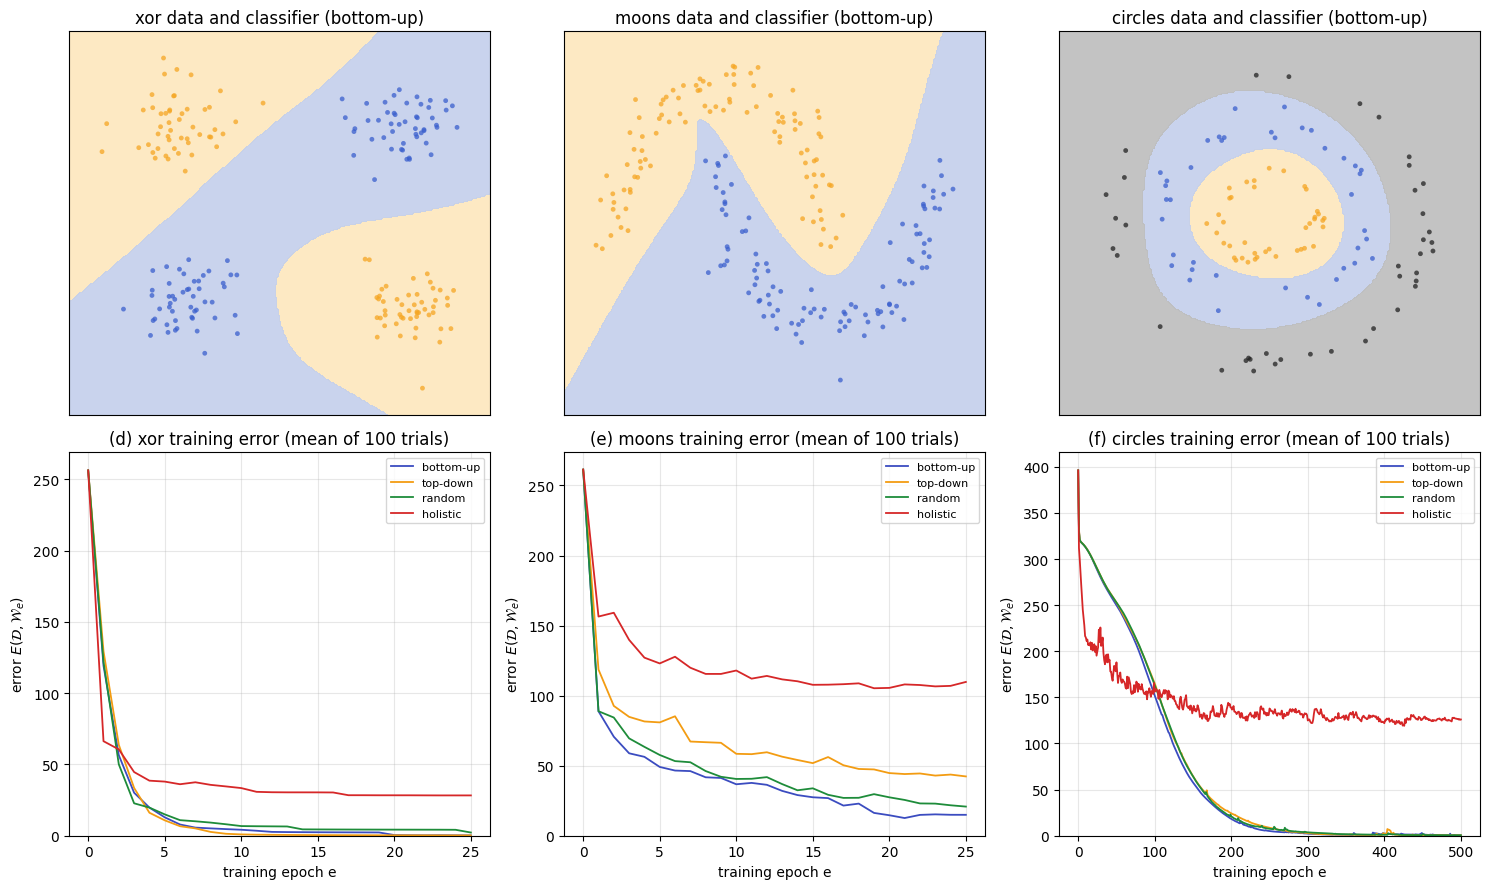

In [13]:
VARIANT_COLORS = {"bottom-up": "#3b4cc0", "top-down": "#f39c12", "random": "#1e8c3a", "holistic": "#d62728"}


@torch.no_grad()
def plot_boundary(ax, name):
    d = DATASETS[name]
    params, final_err = FIG1_PARAMS[name]
    best = int(np.argmin(final_err))
    params = [q[best:best + 1] for q in params]
    xs = d.x.numpy()
    g0, g1 = np.meshgrid(np.linspace(xs[:, 0].min() - .3, xs[:, 0].max() + .3, 300),
                         np.linspace(xs[:, 1].min() - .3, xs[:, 1].max() + .3, 300))
    grid = torch.tensor(np.stack([g0.ravel(), g1.ravel()], 1), dtype=torch.float32)
    pred = predict_classes(grid, params, FIG1[name]["beta"])[0].numpy().reshape(g0.shape)
    ax.contourf(g0, g1, pred, levels=np.arange(d.n_classes + 1) - .5,
                cmap=ListedColormap(REGION_COLORS[:d.n_classes]), alpha=.9)
    for k in range(d.n_classes):
        m = (d.labels == k).numpy()
        ax.scatter(xs[m, 0], xs[m, 1], s=12, c=CLASS_COLORS[k], alpha=.75, edgecolors="none")
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{name} data and classifier (bottom-up)")


fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for j, name in enumerate(FIG1_RESULTS):
    plot_boundary(axes[0, j], name)
    ax = axes[1, j]
    for variant, h in FIG1_RESULTS[name].items():
        e = np.array(h["error"])
        ax.plot(e.mean(axis=1), label=variant, color=VARIANT_COLORS[variant], lw=1.3)
    ax.set_title(f"({'def'[j]}) {name} training error (mean of {FIG1[name]['trials']} trials)")
    ax.set_xlabel("training epoch e"); ax.set_ylabel(r"error $E(\mathcal{D}, \mathcal{W}_e)$")
    ax.set_ylim(bottom=0); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "fig1.png", dpi=150)
plt.show()

In [14]:
rows = []
for name, res in FIG1_RESULTS.items():
    for variant, h in res.items():
        e, acc = np.array(h["error"]), np.array(h["train_acc"][-1])
        rows.append((name, variant, e[0].mean(), e[-1].mean(), np.median(e[-1]), acc.mean(),
                     (acc >= 0.95).mean(), h["time"][-1]))
print(f"{'data':8s} {'variant':10s} {'E start':>8s} {'E final':>8s} {'median':>8s} {'acc':>6s} {'>=95%':>6s} {'time':>7s}")
for r in rows:
    print(f"{r[0]:8s} {r[1]:10s} {r[2]:8.1f} {r[3]:8.2f} {r[4]:8.2f} {r[5]:6.3f} {r[6]:6.0%} {r[7]:6.0f}s")

data     variant     E start  E final   median    acc  >=95%    time
xor      bottom-up     256.2     0.24     0.17  1.000   100%     19s
xor      top-down      256.2     0.22     0.18  1.000   100%     19s
xor      random        256.2     2.24     0.18  0.998    99%     52s
xor      holistic      256.2    28.27     0.04  0.965    86%     40s
moons    bottom-up     261.3    14.92     0.19  0.979    86%     19s
moons    top-down      261.3    42.33     0.21  0.942    76%     19s
moons    random        261.3    20.80     0.15  0.971    85%     51s
moons    holistic      261.3   109.77    60.00  0.861    37%     48s
circles  bottom-up     396.0     0.43     0.39  1.000   100%    555s
circles  top-down      396.0     0.45     0.42  1.000   100%    635s
circles  random        396.0     0.49     0.40  1.000   100%   2134s
circles  holistic      396.0   125.98    70.97  0.817    40%   1908s


**What to look for (the paper's two conclusions):**
1. Layer-wise SPSA (blue, orange, green) learns much better than holistic SPSA (red). Holistic gets
   many trials stuck, so its mean error stays high.
2. The three layer orders behave almost identically.

## 6. Sect. 4.2: MNIST (Fig. 2)

### Data

The original IDX files are downloaded once from a public mirror and cached as `mnist.npz`. Pixels are
scaled to [0, 1] and flattened to 784 values; labels are one-hot in $\{0,1\}^{10}$. The full
60k / 10k split is used.

If the download fails (no internet), put the four `*-ubyte.gz` files into the data directory by hand.

train (60000, 784) test (10000, 784) pixel range 0.0 1.0


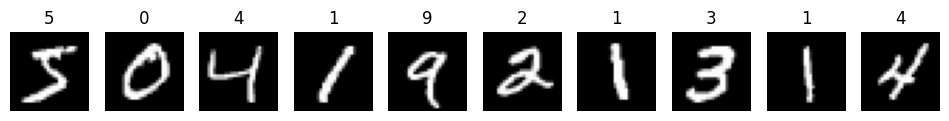

In [15]:
MNIST_FILES = {"train_images": "train-images-idx3-ubyte", "train_labels": "train-labels-idx1-ubyte",
               "test_images": "t10k-images-idx3-ubyte", "test_labels": "t10k-labels-idx1-ubyte"}
MNIST_MIRRORS = ("https://ossci-datasets.s3.amazonaws.com/mnist/",
                 "https://storage.googleapis.com/cvdf-datasets/mnist/",
                 "http://yann.lecun.com/exdb/mnist/")
MNIST_DIR = DATA_DIR / "mnist"
MNIST_DIR.mkdir(parents=True, exist_ok=True)


def _read_idx(path):
    with (gzip.open if path.suffix == ".gz" else open)(path, "rb") as f:
        data = f.read()
    ndim = data[3]
    dims = [int.from_bytes(data[4 + 4 * i: 8 + 4 * i], "big") for i in range(ndim)]
    return np.frombuffer(data, dtype=np.uint8, offset=4 + 4 * ndim).reshape(dims)


def _get_file(stem):
    for name in (stem, stem + ".gz"):
        for folder in (MNIST_DIR, MNIST_DIR / "raw", MNIST_DIR / "MNIST" / "raw"):
            if (folder / name).exists():
                return folder / name
    target = MNIST_DIR / (stem + ".gz")
    for mirror in MNIST_MIRRORS:
        try:
            print("downloading", mirror + stem + ".gz")
            req = urllib.request.Request(mirror + stem + ".gz", headers={"User-Agent": "python-urllib"})
            with urllib.request.urlopen(req, timeout=60) as r, open(target, "wb") as f:
                shutil.copyfileobj(r, f)
            return target
        except Exception as exc:
            print("  failed:", exc)
            target.unlink(missing_ok=True)
    raise RuntimeError(f"Could not download {stem}; place it into {MNIST_DIR} by hand.")


cache = MNIST_DIR / "mnist.npz"
if not cache.exists():
    np.savez_compressed(cache, **{k: _read_idx(_get_file(s)) for k, s in MNIST_FILES.items()})
with np.load(cache) as z:
    arr = {k: z[k] for k in z.files}


def to_dataset(images, labels, n=None):
    if n is not None:
        images, labels = images[:n], labels[:n]
    x = torch.tensor(images.reshape(len(images), -1), dtype=torch.float32) / 255.0
    lab = torch.tensor(labels.astype(np.int64))
    return Dataset(x, torch.nn.functional.one_hot(lab, 10).float(), lab, 10)


MNIST_TRAIN = to_dataset(arr["train_images"], arr["train_labels"], 10000 if QUICK else None)
MNIST_TEST = to_dataset(arr["test_images"], arr["test_labels"])
print("train", tuple(MNIST_TRAIN.x.shape), "test", tuple(MNIST_TEST.x.shape),
      "pixel range", MNIST_TRAIN.x.min().item(), MNIST_TRAIN.x.max().item())

fig, axes = plt.subplots(1, 10, figsize=(12, 1.5))
for i, ax in enumerate(axes):
    ax.imshow(MNIST_TRAIN.x[i].view(28, 28), cmap="gray"); ax.set_title(int(MNIST_TRAIN.labels[i])); ax.axis("off")
plt.show()

### Settings

**From the paper:**
* 771,270 parameters, here realised as a 784×784×196×10 network with tanh units (β = 1); the prose
  topology 784×196×10 is compared in Section 7b;
* the **bottom-up** order;
* **weights first, then biases**, as two SPSA calls per layer;
* $a = 0.1$, $c = 0.1$, $t_{max} = 50$;
* 12 SPSA epochs;
* a gradient-descent baseline with learning rate 0.01.

**Not in the paper, chosen here:**
* $\alpha = 0.602$, $\gamma = 0.101$: Spall's recommended values, from the overview cited by the
  authors' TensorFlow optimizer.
* Inside SPSA, the objective is the TF-style `reduce_mean` of the squared residuals (Eq. 9 / (n·10)).
  With Eq. 9 / n, the paper's $a = 0.1$ makes the error blow up.
* The logged error is Eq. 9 / n, the y-axis scale of Fig. 2.
* Glorot initialisation, which gives the initial error of ≈ 2.5 seen in Fig. 2.
* Full-batch GD, whose slow curve matches the GD curve in Fig. 2.
* `MNIST_RUNS = 3` SPSA runs are trained in parallel as 3 trials.

In [16]:
xtr, ytr, ltr = MNIST_TRAIN.x.to(DEVICE), MNIST_TRAIN.y.to(DEVICE), MNIST_TRAIN.labels.to(DEVICE)
xte, lte = MNIST_TEST.x.to(DEVICE), MNIST_TEST.labels.to(DEVICE)
MNIST_SIZES = [784, 784, 196, 10]      # 771,270 parameters (paper's count)
MNIST_EPOCHS = 3 if QUICK else 12
GD_EPOCHS = 20 if QUICK else 250
mnist_eval = lambda q: {"test_acc": accuracy(xte, lte, q, 1.0), "train_acc": accuracy(xtr, ltr, q, 1.0)}


def mnist_spsa(order="bottom-up", split_bias=True, tag="[SPSA] ", sizes=None):
    cfg = TrainConfig(sizes=sizes or MNIST_SIZES, order=order, epochs=MNIST_EPOCHS, beta=1.0, n_trials=MNIST_RUNS,
                      reduction="elementwise_mean", report_reduction="mean", split_bias=split_bias,
                      init="glorot", seed=SEED,
                      spsa=SPSAConfig(a=0.1, c=0.1, alpha=0.602, gamma=0.101, t_max=50))
    _, hist = train_spsa(xtr, ytr, cfg, eval_fn=mnist_eval, log_every=1, tag=tag)
    return {"config": asdict(cfg), **hist}


print(f"network {'x'.join(map(str, MNIST_SIZES))}: {count_parameters(MNIST_SIZES):,d} parameters")
MNIST_RESULTS = {"spsa": mnist_spsa()}
print("final test accuracy per run:", [round(v, 4) for v in MNIST_RESULTS["spsa"]["test_acc"][-1]])

network 784x784x196x10: 771,270 parameters


[SPSA] epoch    1/12  E mean     2.144  median     2.069  test_acc 0.2655  train_acc 0.2689  (24.9s)


[SPSA] epoch    2/12  E mean     2.216  median     2.050  test_acc 0.3754  train_acc 0.3783  (48.6s)


[SPSA] epoch    3/12  E mean     2.379  median     2.441  test_acc 0.4314  train_acc 0.4248  (72.5s)


[SPSA] epoch    4/12  E mean     2.352  median     2.361  test_acc 0.4828  train_acc 0.4728  (96.4s)


[SPSA] epoch    5/12  E mean     2.418  median     2.467  test_acc 0.4978  train_acc 0.4899  (120.3s)


... (4 outputs left out)

[SPSA] epoch   10/12  E mean     2.717  median     2.745  test_acc 0.5075  train_acc 0.5039  (240.3s)


[SPSA] epoch   11/12  E mean     2.759  median     2.790  test_acc 0.5144  train_acc 0.5133  (264.3s)


[SPSA] epoch   12/12  E mean     2.779  median     2.793  test_acc 0.5149  train_acc 0.5092  (288.4s)


final test accuracy per run: [0.4811, 0.5584, 0.5053]


### Gradient-descent baseline (with backpropagation)

The same network and initialisation, trained by full-batch gradient descent on the per-sample-mean
error. This mirrors `tf.train.GradientDescentOptimizer(0.01)`. It is the only place in the notebook
where gradients are computed.

In [17]:
def train_gd(x, y, sizes, lr=0.01, epochs=250, beta=1.0, seed=SEED, eval_fn=None, log_every=25):
    gen = make_generator(seed)
    params = init_params(sizes, 1, "glorot", DEVICE, x.dtype, gen)
    for p in params:
        p.requires_grad_(True)
    hist = {"error": [], "time": []}

    def record(elapsed):
        with torch.no_grad():
            hist["error"].append(evaluate_error(x, y, params, beta, "mean").cpu().tolist())
            hist["time"].append(elapsed)
            for k, v in (eval_fn(params) if eval_fn else {}).items():
                hist.setdefault(k, []).append(v.cpu().tolist())

    t0 = time.perf_counter()
    record(0.0)
    for e in range(1, epochs + 1):
        loss = error(forward(x, params, beta), y, "mean").sum()
        grads = torch.autograd.grad(loss, params)
        with torch.no_grad():
            for p, g in zip(params, grads):
                p.sub_(lr * g)
        record(time.perf_counter() - t0)
        if e % log_every == 0 or e == epochs:
            print(f"[GD] epoch {e:4d}/{epochs}  E {hist['error'][-1][0]:.4f}  test_acc {hist['test_acc'][-1][0]:.4f}"
                  f"  ({hist['time'][-1]:.1f}s)", flush=True)
    return hist


MNIST_RESULTS["gd"] = {"config": dict(lr=0.01, epochs=GD_EPOCHS, batch="full"),
                       **train_gd(xtr, ytr, MNIST_SIZES, lr=0.01, epochs=GD_EPOCHS, eval_fn=mnist_eval)}
with open(RESULTS_DIR / "mnist.json", "w") as f:
    json.dump(MNIST_RESULTS, f)

[GD] epoch   25/250  E 1.4031  test_acc 0.4249  (4.4s)


[GD] epoch   50/250  E 0.9413  test_acc 0.6284  (8.1s)


[GD] epoch   75/250  E 0.8115  test_acc 0.6776  (11.8s)


[GD] epoch  100/250  E 0.6086  test_acc 0.7941  (15.6s)


[GD] epoch  125/250  E 0.5439  test_acc 0.8101  (19.3s)


[GD] epoch  150/250  E 0.5150  test_acc 0.8317  (23.0s)


[GD] epoch  175/250  E 0.4974  test_acc 0.8347  (26.8s)


[GD] epoch  200/250  E 0.4865  test_acc 0.8420  (30.5s)


[GD] epoch  225/250  E 0.4861  test_acc 0.8375  (34.3s)


[GD] epoch  250/250  E 0.4801  test_acc 0.8480  (38.0s)


### Figure 2

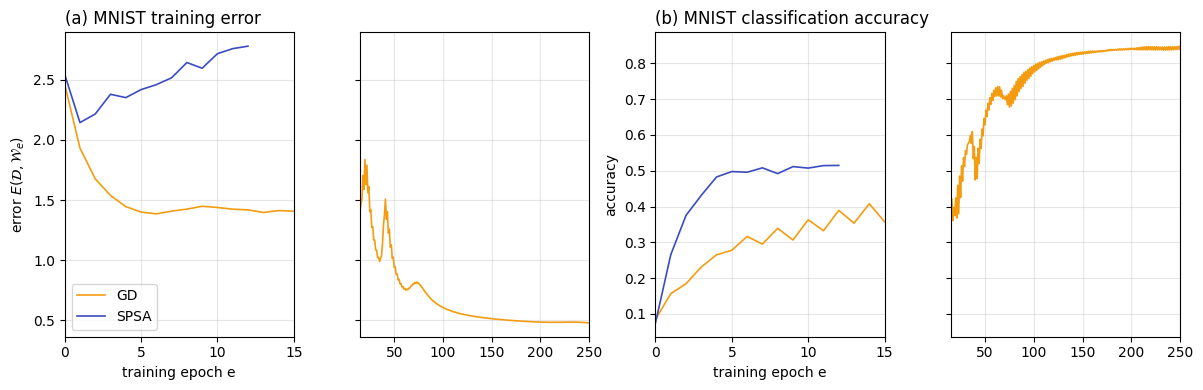

In [18]:
def plot_fig2(spsa, gd, path):
    fig = plt.figure(figsize=(12, 4))
    split = 15
    for i, (key, ylabel, title) in enumerate([("error", r"error $E(\mathcal{D}, \mathcal{W}_e)$", "(a) MNIST training error"),
                                              ("test_acc", "accuracy", "(b) MNIST classification accuracy")]):
        left = fig.add_subplot(1, 4, 2 * i + 1)
        right = fig.add_subplot(1, 4, 2 * i + 2, sharey=left)
        for label, h, color in (("GD", gd, "#f39c12"), ("SPSA", spsa, "#3b4cc0")):
            if h is None:
                continue
            v = np.array(h[key]).mean(axis=1)
            left.plot(np.arange(min(len(v), split + 1)), v[:split + 1], color=color, label=label, lw=1.2)
            if len(v) > split:
                right.plot(np.arange(split, len(v)), v[split:], color=color, lw=1.2)
        left.set_xlim(0, split); left.set_xlabel("training epoch e"); left.set_ylabel(ylabel)
        left.set_title(title, loc="left"); left.grid(alpha=.3); right.grid(alpha=.3)
        right.tick_params(labelleft=False)
        if gd is not None and len(gd[key]) > split:
            right.set_xlim(split, len(gd[key]) - 1)
        else:
            right.set_visible(False)
        if i == 0:
            left.legend()
    plt.tight_layout(); plt.savefig(path, dpi=150); plt.show()


plot_fig2(MNIST_RESULTS["spsa"], MNIST_RESULTS["gd"], RESULTS_DIR / "fig2.png")

**What to look for:** SPSA, using forward passes only, gains accuracy much faster than gradient
descent over the first 12 epochs. Gradient descent keeps improving and ends higher after 250 epochs.

## 7. MNIST ablations stated in the text of Sect. 4.2

The paper makes two further claims without showing curves:
1. *"the holistic variant of SPSA failed to learn the MNIST task"*;
2. without updating weights and biases in separate SPSA calls, *"we did not observe any learning behavior"*.

--- holistic SPSA ---


[holistic] epoch    1/12  E mean     4.923  median     5.097  test_acc 0.2325  train_acc 0.2296  (27.0s)


[holistic] epoch    2/12  E mean     5.499  median     5.597  test_acc 0.2734  train_acc 0.2680  (55.3s)


[holistic] epoch    3/12  E mean     5.436  median     5.326  test_acc 0.3187  train_acc 0.3132  (83.6s)


[holistic] epoch    4/12  E mean     5.538  median     5.463  test_acc 0.3528  train_acc 0.3478  (111.9s)


[holistic] epoch    5/12  E mean     5.438  median     5.451  test_acc 0.3934  train_acc 0.3871  (140.1s)


... (16 outputs left out)

[no split] epoch    9/12  E mean     2.693  median     2.655  test_acc 0.5223  train_acc 0.5093  (109.5s)


[no split] epoch   10/12  E mean     2.671  median     2.620  test_acc 0.5251  train_acc 0.5166  (121.7s)


[no split] epoch   11/12  E mean     2.718  median     2.761  test_acc 0.5315  train_acc 0.5195  (134.0s)


[no split] epoch   12/12  E mean     2.709  median     2.776  test_acc 0.5269  train_acc 0.5174  (146.1s)


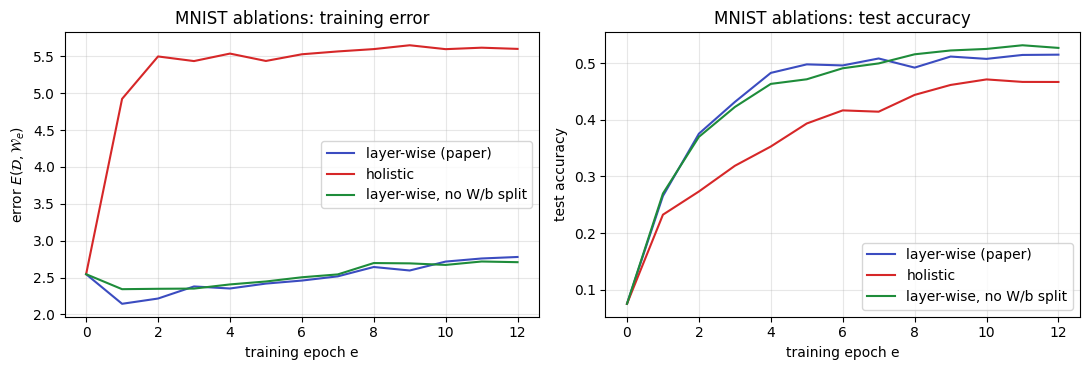

In [19]:
print("--- holistic SPSA ---")
MNIST_RESULTS["spsa_holistic"] = mnist_spsa(order="holistic", tag="[holistic] ")
print("\n--- bottom-up SPSA without the weights/biases split ---")
MNIST_RESULTS["spsa_no_split_bias"] = mnist_spsa(split_bias=False, tag="[no split] ")
with open(RESULTS_DIR / "mnist.json", "w") as f:
    json.dump(MNIST_RESULTS, f)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for key, label, color in (("spsa", "layer-wise (paper)", "#3b4cc0"), ("spsa_holistic", "holistic", "#d62728"),
                          ("spsa_no_split_bias", "layer-wise, no W/b split", "#1e8c3a")):
    h = MNIST_RESULTS[key]
    axes[0].plot(np.array(h["error"]).mean(1), label=label, color=color)
    axes[1].plot(np.array(h["test_acc"]).mean(1), label=label, color=color)
axes[0].set_ylabel(r"error $E(\mathcal{D}, \mathcal{W}_e)$"); axes[1].set_ylabel("test accuracy")
for ax in axes:
    ax.set_xlabel("training epoch e"); ax.grid(alpha=.3); ax.legend()
axes[0].set_title("MNIST ablations: training error"); axes[1].set_title("MNIST ablations: test accuracy")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "fig_mnist_ablations.png", dpi=150); plt.show()

## 7b. The literal text topology: 784×196×10 (155,830 parameters)

The same SPSA and GD protocol on the network exactly as the paper's prose describes it. This shows
how much the choice between the two readings matters.

network 784x196x10: 155,830 parameters


[SPSA 155k] epoch    1/12  E mean     2.305  median     2.335  test_acc 0.1950  train_acc 0.1945  (5.5s)


[SPSA 155k] epoch    2/12  E mean     2.166  median     2.265  test_acc 0.2596  train_acc 0.2603  (10.3s)


[SPSA 155k] epoch    3/12  E mean     2.075  median     2.157  test_acc 0.2988  train_acc 0.2999  (15.2s)


[SPSA 155k] epoch    4/12  E mean     2.095  median     2.105  test_acc 0.3581  train_acc 0.3578  (20.0s)


[SPSA 155k] epoch    5/12  E mean     2.080  median     2.107  test_acc 0.4071  train_acc 0.4066  (24.9s)


... (13 outputs left out)

[GD] epoch  175/250  E 0.5935  test_acc 0.7792  (6.2s)


[GD] epoch  200/250  E 0.5758  test_acc 0.7900  (7.2s)


[GD] epoch  225/250  E 0.5610  test_acc 0.7982  (8.1s)


[GD] epoch  250/250  E 0.5485  test_acc 0.8050  (9.0s)


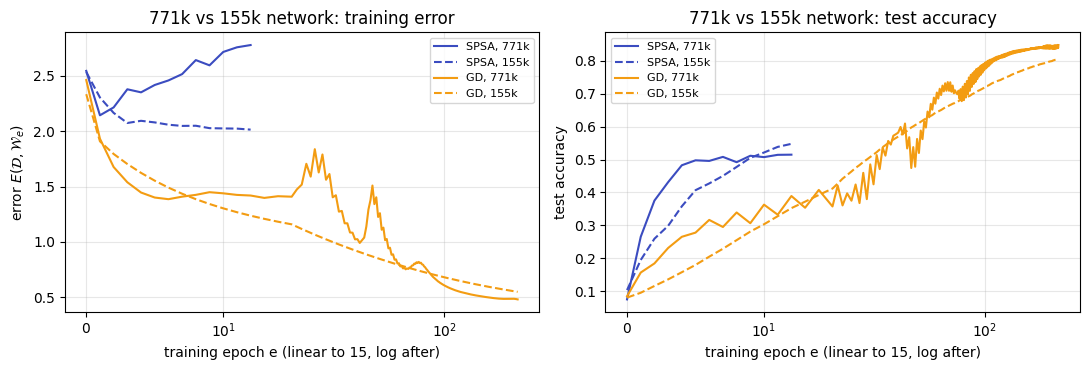

In [20]:
SIZES_155K = [784, 196, 10]
print(f"network {'x'.join(map(str, SIZES_155K))}: {count_parameters(SIZES_155K):,d} parameters")
MNIST_RESULTS["spsa_155k"] = mnist_spsa(sizes=SIZES_155K, tag="[SPSA 155k] ")
MNIST_RESULTS["gd_155k"] = {"config": dict(lr=0.01, epochs=GD_EPOCHS, batch="full", sizes=SIZES_155K),
                            **train_gd(xtr, ytr, SIZES_155K, lr=0.01, epochs=GD_EPOCHS, eval_fn=mnist_eval)}
with open(RESULTS_DIR / "mnist.json", "w") as f:
    json.dump(MNIST_RESULTS, f)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for key, label, color, ls in (("spsa", "SPSA, 771k", "#3b4cc0", "-"), ("spsa_155k", "SPSA, 155k", "#3b4cc0", "--"),
                              ("gd", "GD, 771k", "#f39c12", "-"), ("gd_155k", "GD, 155k", "#f39c12", "--")):
    h = MNIST_RESULTS[key]
    n = MNIST_EPOCHS + 1 if key.startswith("spsa") else len(h["error"])
    axes[0].plot(np.array(h["error"]).mean(1)[:n], label=label, color=color, ls=ls)
    axes[1].plot(np.array(h["test_acc"]).mean(1)[:n], label=label, color=color, ls=ls)
for ax, yl in zip(axes, (r"error $E(\mathcal{D}, \mathcal{W}_e)$", "test accuracy")):
    ax.set_xscale("symlog", linthresh=15); ax.set_xlabel("training epoch e (linear to 15, log after)")
    ax.set_ylabel(yl); ax.grid(alpha=.3); ax.legend(fontsize=8)
axes[0].set_title("771k vs 155k network: training error"); axes[1].set_title("771k vs 155k network: test accuracy")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "fig_mnist_771k_vs_155k.png", dpi=150); plt.show()

## 8. Summary and comparison with the paper

In [21]:
def final_acc(key, epoch=None):
    acc = np.array(MNIST_RESULTS[key]["test_acc"])
    return acc[min(epoch, len(acc) - 1)] if epoch is not None else acc[-1]

print("MNIST (test accuracy)")
print(f"  {'run':36s} {'epoch 12 (per run)':>26s} {'final mean':>11s}  E start -> final")
for key, label in (("spsa", "771k: layer-wise SPSA (paper setup)"), ("gd", "771k: gradient descent"),
                   ("spsa_holistic", "771k: holistic SPSA"), ("spsa_no_split_bias", "771k: SPSA, no W/b split"),
                   ("spsa_155k", "155k: layer-wise SPSA"), ("gd_155k", "155k: gradient descent")):
    e = np.array(MNIST_RESULTS[key]["error"])
    at12 = ", ".join(f"{v:.3f}" for v in final_acc(key, 12))
    print(f"  {label:36s} {at12:>26s} {final_acc(key).mean():11.3f}  {e[0].mean():.2f} -> {e[-1].mean():.2f}")

lw = {n: min(np.array(r[v]["error"][-1]).mean() for v in ("bottom-up", "top-down", "random")) for n, r in FIG1_RESULTS.items()}
ho = {n: np.array(r["holistic"]["error"][-1]).mean() for n, r in FIG1_RESULTS.items()}
print("\nFig. 1 (final mean error): " + ", ".join(f"{n}: layer-wise {lw[n]:.2f} vs holistic {ho[n]:.2f}" for n in lw))
print(f"\ntotal notebook run time: {(time.perf_counter() - NOTEBOOK_T0) / 60:.1f} min")
print("results saved in", RESULTS_DIR.resolve())

MNIST (test accuracy)
  run                                          epoch 12 (per run)  final mean  E start -> final
  771k: layer-wise SPSA (paper setup)         0.481, 0.558, 0.505       0.515  2.55 -> 2.78
  771k: gradient descent                                    0.389       0.848  2.46 -> 0.48
  771k: holistic SPSA                         0.465, 0.408, 0.527       0.467  2.55 -> 5.60
  771k: SPSA, no W/b split                    0.524, 0.484, 0.572       0.527  2.55 -> 2.71
  155k: layer-wise SPSA                       0.519, 0.566, 0.558       0.548  2.54 -> 2.01
  155k: gradient descent                                    0.352       0.805  2.34 -> 0.55

Fig. 1 (final mean error): xor: layer-wise 0.22 vs holistic 28.27, moons: layer-wise 14.92 vs holistic 109.77, circles: layer-wise 0.43 vs holistic 125.98

total notebook run time: 106.6 min
results saved in D:\SPSA implementation\spsa-layerwise\notebooks\notebook_results


### Reproduction status

These are the results from the paper-protocol run on an RTX 3050 laptop GPU; the printed output
above is from your run. For checking a run, the main signs to compare are holistic vs. layer-wise and
SPSA vs. GD at epoch 12.

| paper result | reproduced? |
|---|---|
| Fig. 1: layer-wise SPSA beats holistic SPSA on xor, moons, circles | ✅ yes: holistic stays far higher on all three |
| Fig. 1: the layer order (bottom-up / top-down / random) does not matter | ✅ yes: the curves overlap |
| Fig. 1: holistic training does not converge on circles | ✅ yes: about 40 % of trials solved vs 100 % for layer-wise |
| Fig. 2: SPSA learns faster than GD in the first epochs | ✅ yes: ≈ 0.52 vs ≈ 0.39 test accuracy at epoch 12 (771k network) |
| Fig. 2: GD ends higher after long training | ✅ yes: ≈ 0.85 after 250 epochs |
| Fig. 2: SPSA reaches ≈ 0.72 at epoch 12, with falling training error | ⚠️ partly: ≈ 0.52, and the training error rises (2.55 → 2.78). The paper does not give its init, loss scale and gain schedule |
| Sect. 4.2: holistic SPSA fails on MNIST | ⚠️ partly: the training error blows up (2.55 → 5.60), but accuracy still climbs to ≈ 0.47 |
| Sect. 4.2: no learning without the weights/biases split | ❌ no: learning works just as well without the split (≈ 0.53) |
| Sect. 4.2: 771,270 parameters | ✅ count matched with 784×784×196×10; the literal 784×196×10 (155,830) does slightly better with SPSA (≈ 0.55, Section 7b) |

**Key takeaway.** Neural networks can be trained with forward passes only. Two random perturbations
per step are enough when the parameter space being probed is kept small, by updating one layer (or
one weight block) at a time. Perturbing all parameters at once suffers from the curse of
dimensionality, as the paper argues.